In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis

# Set graph appearance
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
file_path = "/content/data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (4600, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [ ]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Column Names:
['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country']

Data Types:
date              object
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
street            object
city              object
statezip          object
country           object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nZero Price Records:")
print((df["price"] == 0).sum())

Missing Values:
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

Duplicate Records:
0

Zero Price Records:
49


In [ ]:
# Keep only records with positive house prices
clean_df = df[df["price"] > 0].copy()

print("Original records:", len(df))
print("Cleaned records:", len(clean_df))
print("Excluded records:", len(df) - len(clean_df))

# Check the cleaned data
clean_df.head()

Original records: 4600
Cleaned records: 4551
Excluded records: 49


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [ ]:
mean_price = clean_df["price"].mean()

median_price = clean_df["price"].median()

std_price = clean_df["price"].std()

variance_price = clean_df["price"].var()

skewness_price = skew(clean_df["price"])

kurtosis_price = kurtosis(clean_df["price"])

print("HOUSE PRICE STATISTICS")
print("----------------------")

print("Mean:", round(mean_price, 2))
print("Median:", round(median_price, 2))
print("Standard Deviation:", round(std_price, 2))
print("Variance:", round(variance_price, 2))
print("Skewness:", round(skewness_price, 2))
print("Excess Kurtosis:", round(kurtosis_price, 2))

HOUSE PRICE STATISTICS
----------------------
Mean: 557905.9
Median: 465000.0
Standard Deviation: 563929.87
Variance: 318016899720.96
Skewness: 25.02
Excess Kurtosis: 1052.71


Number of houses in each price range:
price_range
0–250K        515
250K–500K    2033
500K–750K    1209
750K–1M       454
1M–1.5M       224
1.5M–2M        69
Above 2M       47
Name: count, dtype: int64


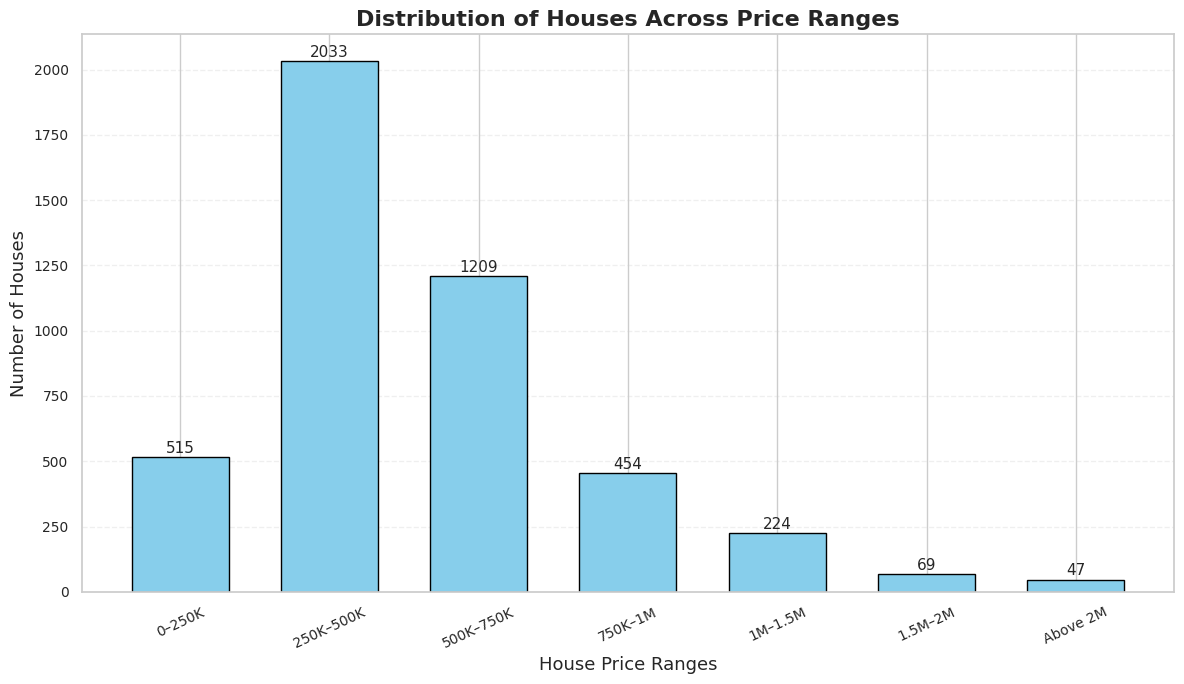

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Define house price ranges
bins = [
    0, 250000, 500000, 750000,
    1000000, 1500000, 2000000, float("inf")
]

labels = [
    "0–250K",
    "250K–500K",
    "500K–750K",
    "750K–1M",
    "1M–1.5M",
    "1.5M–2M",
    "Above 2M"
]

# Step 2: Categorise house prices
clean_df["price_range"] = pd.cut(
    clean_df["price"],
    bins=bins,
    labels=labels,
    right=True
)

# Step 3: Count houses in each price range
price_counts = clean_df["price_range"].value_counts(
    sort=False
)

print("Number of houses in each price range:")
print(price_counts)

# Step 4: Plot the bar chart
plt.figure(figsize=(12, 7))

bars = plt.bar(
    price_counts.index.astype(str),
    price_counts.values,
    color="skyblue",
    edgecolor="black",
    width=0.65
)

# Step 5: Display values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=11
    )

# Step 6: Add title and labels
plt.title(
    "Distribution of Houses Across Price Ranges",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("House Price Ranges", fontsize=13)
plt.ylabel("Number of Houses", fontsize=13)

plt.xticks(rotation=25, fontsize=10)
plt.yticks(fontsize=10)

plt.grid(axis="y", linestyle="--", alpha=0.3)

# Step 7: Adjust layout
plt.tight_layout()

# Step 8: Save high-quality graph
plt.savefig(
    "plot1_house_price_barchart.png",
    dpi=300,
    bbox_inches="tight"
)

# Step 9: Display graph
plt.show()

In [ ]:
numerical_columns = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "view",
    "condition",
    "yr_built"
]

correlation_matrix = clean_df[
    numerical_columns
].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,yr_built
price,1.00,0.21,0.34,0.45,0.05,0.15,0.24,0.04,0.02
bedrooms,0.21,1.00,0.55,0.60,0.07,0.18,0.12,0.02,0.14
bathrooms,0.34,0.55,1.00,0.76,0.11,0.49,0.21,-0.12,0.46
sqft_living,0.45,0.60,0.76,1.00,0.21,0.34,0.31,-0.06,0.28
sqft_lot,0.05,0.07,0.11,0.21,1.00,0.00,0.07,0.00,0.05
floors,0.15,0.18,0.49,0.34,0.00,1.00,0.03,-0.27,0.47
view,0.24,0.12,0.21,0.31,0.07,0.03,1.00,0.06,-0.07
condition,0.04,0.02,-0.12,-0.06,0.00,-0.27,0.06,1.00,-0.40
yr_built,0.02,0.14,0.46,0.28,0.05,0.47,-0.07,-0.40,1.00


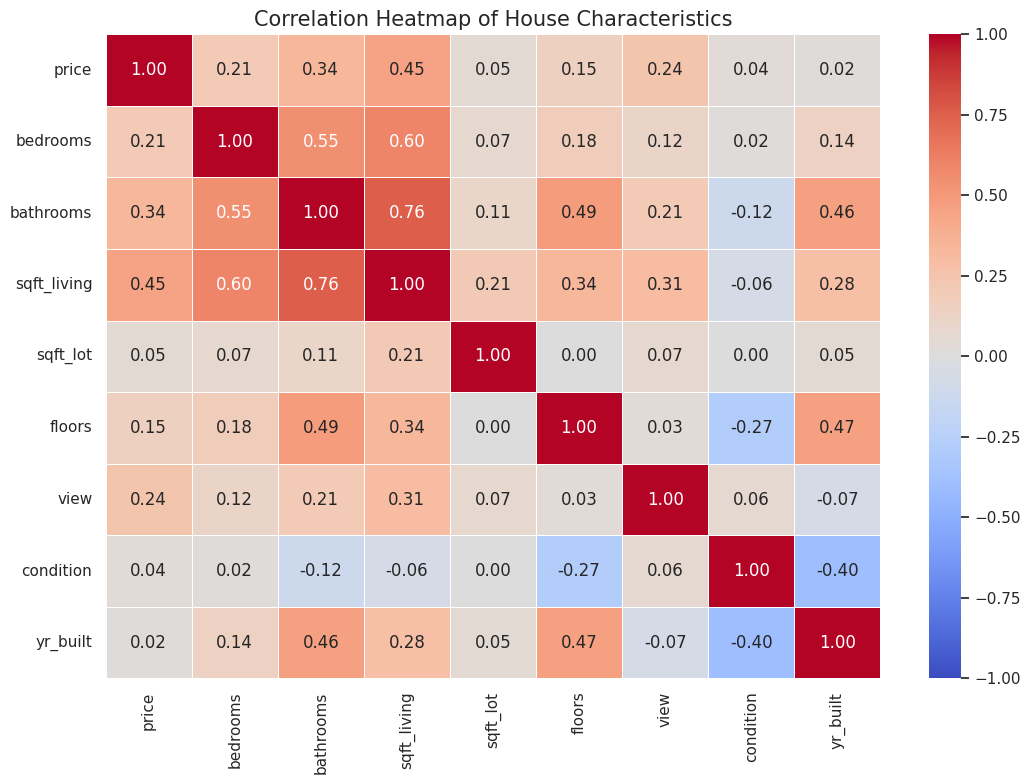

In [ ]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Heatmap of House Characteristics",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "plot3_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

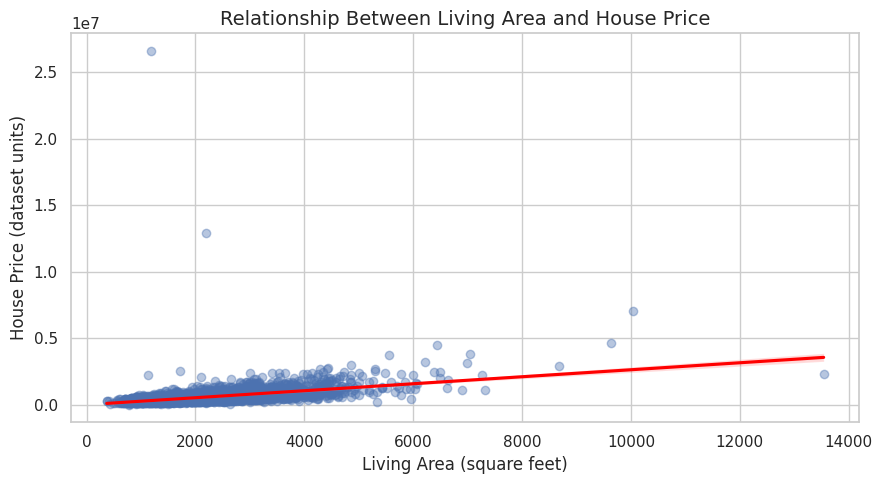

In [ ]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=clean_df,
    x="sqft_living",
    y="price",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title(
    "Relationship Between Living Area and House Price",
    fontsize=14
)

plt.xlabel("Living Area (square feet)")
plt.ylabel("House Price (dataset units)")

plt.tight_layout()

plt.savefig(
    "plot2_living_area_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from google.colab import files

files.download("plot1_house_price_barchart.png")
files.download("plot2_living_area_scatter.png")
files.download("plot3_correlation_heatmap.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>